In [1]:
import numpy as np
import pandas as pd
import joblib
import shap
import sklearn

from pathlib import Path

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SHAP:", shap.__version__)
print("Scikit-learn:", sklearn.__version__)

NumPy: 2.5.4
Pandas: 3.1.1
SHAP: 0.54.1
Scikit-learn: 1.9.1


In [2]:
PROJECT_ROOT = Path.cwd()

# If the notebook is not opened from the project root,
# use the following instead:
if not (PROJECT_ROOT / "models").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_DIR = PROJECT_ROOT / "models"
DATA_DIR = PROJECT_ROOT / "data" / "processed"
RAW_DIR = PROJECT_ROOT / "data" / "raw"

print("Project root:", PROJECT_ROOT)
print("Model directory:", MODEL_DIR)

Project root: c:\Projects\AI_HR_Prediction
Model directory: c:\Projects\AI_HR_Prediction\models


In [3]:
rf_model = joblib.load(
    MODEL_DIR / "random_forest_tuned_model.joblib"
)

lr_model = joblib.load(
    MODEL_DIR / "logistic_regression_tuned_model.joblib"
)

preprocessor = joblib.load(
    MODEL_DIR / "attrition_validation_preprocessor.joblib"
)

print("Random Forest loaded:", type(rf_model).__name__)
print("Logistic Regression loaded:", type(lr_model).__name__)
print("Preprocessor loaded:", type(preprocessor).__name__)

Random Forest loaded: RandomForestClassifier
Logistic Regression loaded: LogisticRegression
Preprocessor loaded: ColumnTransformer


In [4]:
from sklearn.model_selection import train_test_split

df = pd.read_csv(
    RAW_DIR / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
)

X = df.drop(
    columns=[
        "Attrition",
        "EmployeeNumber",
        "EmployeeCount",
        "Over18",
        "StandardHours"
    ]
)

y = df["Attrition"].map({
    "No": 0,
    "Yes": 1
})

# Recreate the original 80:20 stratified split
X_development, X_final_test, y_development, y_final_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

# Recreate the 80:20 development/validation split
X_fit, X_validation, y_fit, y_validation = (
    train_test_split(
        X_development,
        y_development,
        test_size=0.20,
        random_state=42,
        stratify=y_development
    )
)

print("Validation features:", X_validation.shape)
print("Validation labels:", y_validation.shape)

print("\nValidation class distribution:")
print(y_validation.value_counts())

Validation features: (236, 30)
Validation labels: (236,)

Validation class distribution:
Attrition
0    198
1     38
Name: count, dtype: int64


In [5]:
X_validation_processed = preprocessor.transform(
    X_validation
)

print(
    "Processed validation shape:",
    X_validation_processed.shape
)

print(
    "Contains missing values:",
    np.isnan(X_validation_processed).any()
)

Processed validation shape: (236, 51)
Contains missing values: False


In [6]:
rf_predictions = rf_model.predict(
    X_validation_processed
)

lr_predictions = (
    lr_model.predict_proba(X_validation_processed)[:, 1] >= 0.60
).astype(int)

print("Random Forest predictions:", rf_predictions.shape)
print("Logistic Regression predictions:", lr_predictions.shape)

print("\nRandom Forest prediction distribution:")
print(pd.Series(rf_predictions).value_counts())

print("\nLogistic Regression prediction distribution:")
print(pd.Series(lr_predictions).value_counts())

assert len(rf_predictions) == len(y_validation)
assert len(lr_predictions) == len(y_validation)

print("\nModel compatibility verification passed.")

Random Forest predictions: (236,)
Logistic Regression predictions: (236,)

Random Forest prediction distribution:
0    198
1     38
Name: count, dtype: int64

Logistic Regression prediction distribution:
0    176
1     60
Name: count, dtype: int64

Model compatibility verification passed.


In [7]:
# Extract feature names from the fitted preprocessing pipeline

feature_names = preprocessor.get_feature_names_out()

print("Total transformed features:", len(feature_names))

print("\nFirst 20 feature names:")

for i, name in enumerate(feature_names[:20], start=1):
    print(f"{i}. {name}")

Total transformed features: 51

First 20 feature names:
1. num__Age
2. num__DailyRate
3. num__DistanceFromHome
4. num__Education
5. num__EnvironmentSatisfaction
6. num__HourlyRate
7. num__JobInvolvement
8. num__JobLevel
9. num__JobSatisfaction
10. num__MonthlyIncome
11. num__MonthlyRate
12. num__NumCompaniesWorked
13. num__PercentSalaryHike
14. num__PerformanceRating
15. num__RelationshipSatisfaction
16. num__StockOptionLevel
17. num__TotalWorkingYears
18. num__TrainingTimesLastYear
19. num__WorkLifeBalance
20. num__YearsAtCompany


In [8]:
# Convert transformed feature names into a readable DataFrame

feature_mapping = pd.DataFrame({
    "feature_index": range(len(feature_names)),
    "transformed_feature_name": feature_names
})

print(feature_mapping.to_string(index=False))

 feature_index               transformed_feature_name
             0                               num__Age
             1                         num__DailyRate
             2                  num__DistanceFromHome
             3                         num__Education
             4           num__EnvironmentSatisfaction
             5                        num__HourlyRate
             6                    num__JobInvolvement
             7                          num__JobLevel
             8                   num__JobSatisfaction
             9                     num__MonthlyIncome
            10                       num__MonthlyRate
            11                num__NumCompaniesWorked
            12                 num__PercentSalaryHike
            13                 num__PerformanceRating
            14          num__RelationshipSatisfaction
            15                  num__StockOptionLevel
            16                 num__TotalWorkingYears
            17             n

In [9]:
assert len(feature_names) == X_validation_processed.shape[1]

assert X_validation_processed.shape[1] == rf_model.n_features_in_

assert X_validation_processed.shape[1] == lr_model.n_features_in_

print("Feature mapping verification passed.")
print("Feature names:", len(feature_names))
print("Random Forest input features:", rf_model.n_features_in_)
print("Logistic Regression input features:", lr_model.n_features_in_)

Feature mapping verification passed.
Feature names: 51
Random Forest input features: 51
Logistic Regression input features: 51


In [10]:
# Use a representative sample of training data as SHAP background data

background_size = min(100, len(X_fit))

X_background = X_fit.sample(
    n=background_size,
    random_state=42
)

X_background_processed = preprocessor.transform(
    X_background
)

print("Background data shape:", X_background_processed.shape)
print("Validation data shape:", X_validation_processed.shape)

Background data shape: (100, 51)
Validation data shape: (236, 51)


In [11]:
# SHAP explainer for Random Forest

rf_explainer = shap.TreeExplainer(
    rf_model,
    data=X_background_processed,
    model_output="probability",
    feature_perturbation="interventional"
)

print("Random Forest TreeExplainer initialized successfully.")

Random Forest TreeExplainer initialized successfully.


In [12]:
# SHAP explainer for Logistic Regression

lr_explainer = shap.LinearExplainer(
    lr_model,
    X_background_processed
)

print("Logistic Regression LinearExplainer initialized successfully.")

Logistic Regression LinearExplainer initialized successfully.


In [13]:
print("Random Forest base value:")
print(rf_explainer.expected_value)

print("\nLogistic Regression base value:")
print(lr_explainer.expected_value)

Random Forest base value:
[0.68920256 0.31079744]

Logistic Regression base value:
-1.3332708138057092


In [14]:
rf_shap_values = rf_explainer.shap_values(
    X_validation_processed
)

print("SHAP calculation completed.")

print("SHAP output type:", type(rf_shap_values))
print("SHAP output shape:", np.array(rf_shap_values).shape)

SHAP calculation completed.
SHAP output type: <class 'numpy.ndarray'>
SHAP output shape: (236, 51, 2)


In [15]:
# Extract SHAP values for Attrition = Yes

if isinstance(rf_shap_values, list):
    rf_shap_positive = rf_shap_values[1]

else:
    rf_shap_array = np.asarray(rf_shap_values)

    if rf_shap_array.ndim == 3:
        rf_shap_positive = rf_shap_array[:, :, 1]

    elif rf_shap_array.ndim == 2:
        rf_shap_positive = rf_shap_array

    else:
        raise ValueError(
            f"Unexpected SHAP dimensions: {rf_shap_array.shape}"
        )

print("Positive-class SHAP shape:", rf_shap_positive.shape)

assert rf_shap_positive.shape == (236, 51)

print("Random Forest SHAP shape verification passed.")

Positive-class SHAP shape: (236, 51)
Random Forest SHAP shape verification passed.


In [16]:
lr_shap_values = lr_explainer.shap_values(
    X_validation_processed
)

print("Logistic Regression SHAP calculation completed.")
print("SHAP output shape:", np.asarray(lr_shap_values).shape)

lr_shap_positive = np.asarray(lr_shap_values)

assert lr_shap_positive.shape == (236, 51)

print("Logistic Regression SHAP shape verification passed.")

Logistic Regression SHAP calculation completed.
SHAP output shape: (236, 51)
Logistic Regression SHAP shape verification passed.


In [17]:
rf_global_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": np.abs(rf_shap_positive).mean(axis=0)
})

rf_global_importance = rf_global_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

print("RANDOM FOREST - GLOBAL SHAP FEATURE IMPORTANCE")
print("=" * 65)

print(rf_global_importance.head(20).to_string(index=False))

RANDOM FOREST - GLOBAL SHAP FEATURE IMPORTANCE
                               Feature  Mean_Absolute_SHAP
                              num__Age            0.030756
                 num__StockOptionLevel            0.029554
                     cat__OverTime_Yes            0.025861
                      cat__OverTime_No            0.024093
               num__NumCompaniesWorked            0.022759
                    num__MonthlyIncome            0.021733
                         num__JobLevel            0.020929
                   num__YearsAtCompany            0.019080
                 num__DistanceFromHome            0.017565
                num__TotalWorkingYears            0.017457
                        num__DailyRate            0.016020
             num__YearsWithCurrManager            0.015123
                  num__JobSatisfaction            0.014959
                  num__WorkLifeBalance            0.011375
                num__PercentSalaryHike            0.010657
         

In [18]:
lr_global_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": np.abs(lr_shap_positive).mean(axis=0)
})

lr_global_importance = lr_global_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

print("LOGISTIC REGRESSION - GLOBAL SHAP FEATURE IMPORTANCE")
print("=" * 65)

print(lr_global_importance.head(20).to_string(index=False))

LOGISTIC REGRESSION - GLOBAL SHAP FEATURE IMPORTANCE
                              Feature  Mean_Absolute_SHAP
               num__TotalWorkingYears            0.563717
                        num__JobLevel            0.534592
                 num__JobSatisfaction            0.505266
              num__NumCompaniesWorked            0.499053
         num__YearsSinceLastPromotion            0.402696
            num__YearsWithCurrManager            0.370381
                     cat__OverTime_No            0.352363
               num__PercentSalaryHike            0.347143
        num__RelationshipSatisfaction            0.337890
         num__EnvironmentSatisfaction            0.315826
                    cat__OverTime_Yes            0.308474
                             num__Age            0.301612
   cat__JobRole_Laboratory Technician            0.301009
                num__DistanceFromHome            0.273907
                 num__WorkLifeBalance            0.235340
cat__BusinessTravel

In [19]:
shap_comparison = pd.merge(
    rf_global_importance,
    lr_global_importance,
    on="Feature",
    suffixes=("_RandomForest", "_LogisticRegression")
)

shap_comparison = shap_comparison.sort_values(
    by="Mean_Absolute_SHAP_RandomForest",
    ascending=False
).reset_index(drop=True)

print("GLOBAL SHAP IMPORTANCE COMPARISON")
print("=" * 90)

print(shap_comparison.head(20).to_string(index=False))

GLOBAL SHAP IMPORTANCE COMPARISON
                               Feature  Mean_Absolute_SHAP_RandomForest  Mean_Absolute_SHAP_LogisticRegression
                              num__Age                         0.030756                               0.301612
                 num__StockOptionLevel                         0.029554                               0.185094
                     cat__OverTime_Yes                         0.025861                               0.308474
                      cat__OverTime_No                         0.024093                               0.352363
               num__NumCompaniesWorked                         0.022759                               0.499053
                    num__MonthlyIncome                         0.021733                               0.199854
                         num__JobLevel                         0.020929                               0.534592
                   num__YearsAtCompany                         0.019080       

In [20]:
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("SHAP figures directory:", FIGURES_DIR)

SHAP figures directory: c:\Projects\AI_HR_Prediction\reports\figures


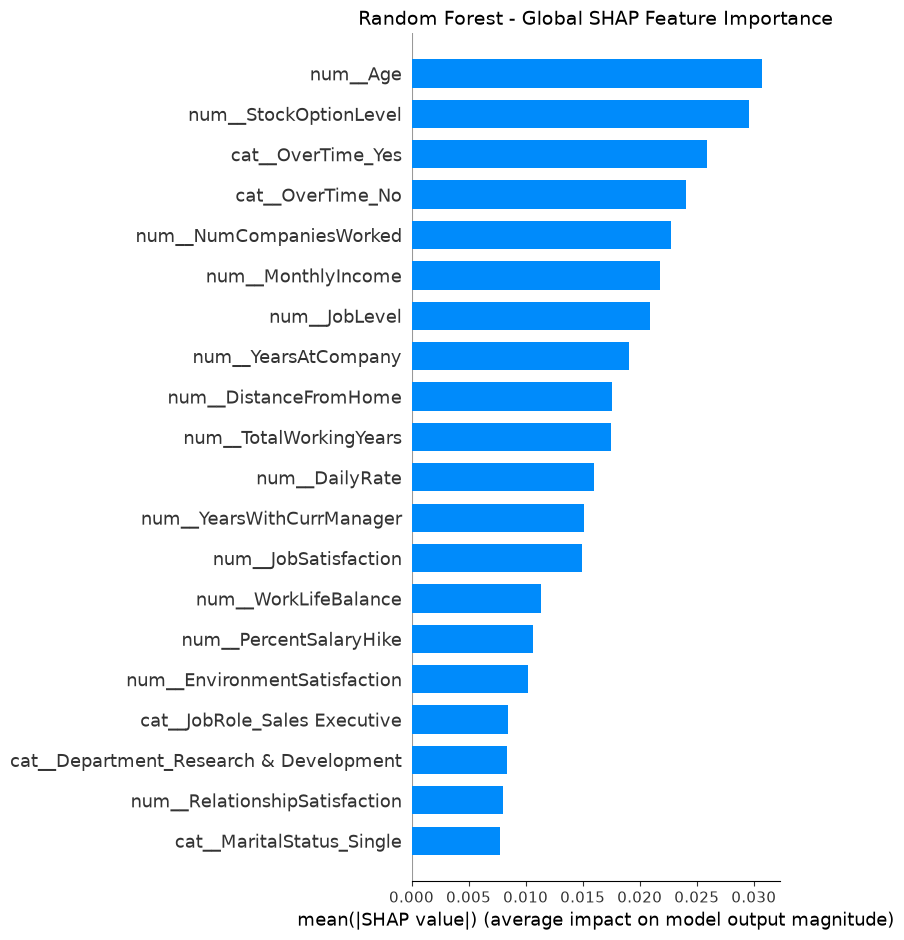

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

shap.summary_plot(
    rf_shap_positive,
    X_validation_processed,
    feature_names=feature_names,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.title(
    "Random Forest - Global SHAP Feature Importance",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "16_rf_shap_global_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

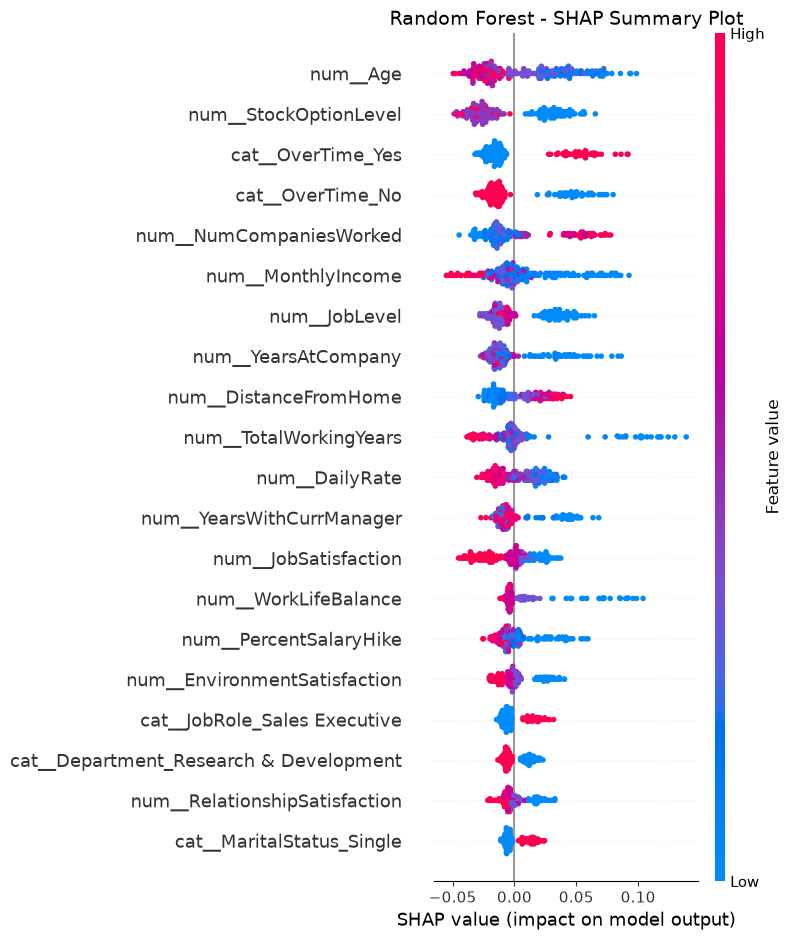

In [22]:
plt.figure(figsize=(12, 9))

shap.summary_plot(
    rf_shap_positive,
    X_validation_processed,
    feature_names=feature_names,
    max_display=20,
    show=False
)

plt.title(
    "Random Forest - SHAP Summary Plot",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "17_rf_shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

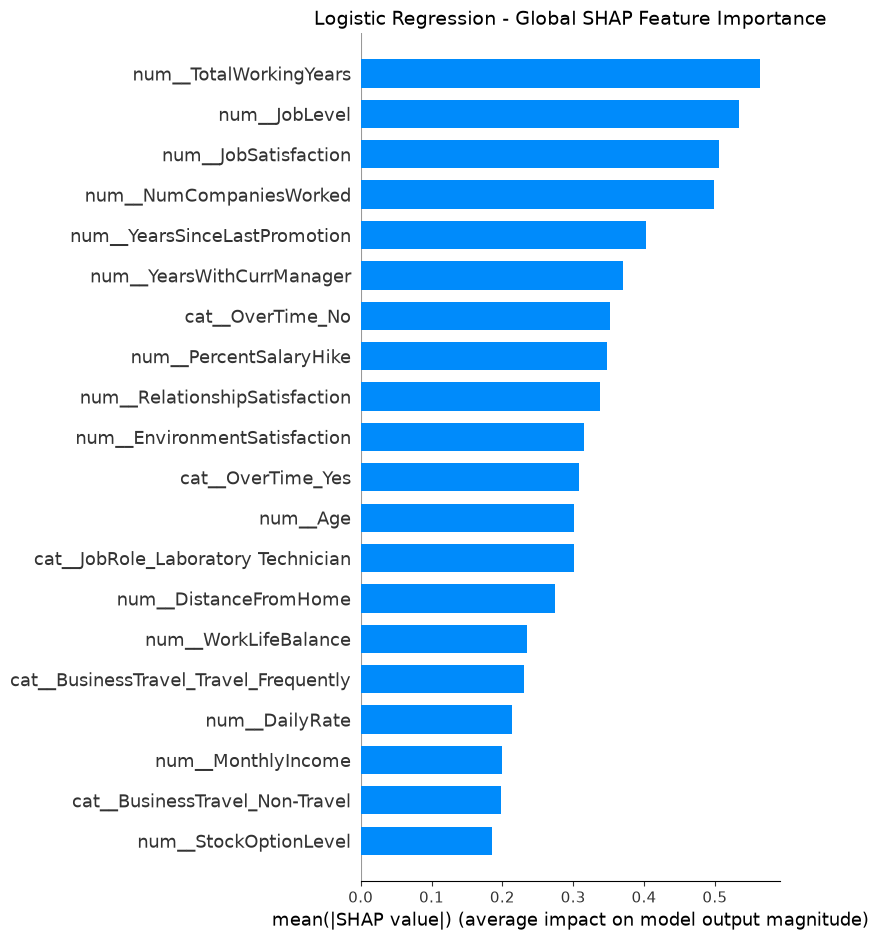

In [23]:
plt.figure(figsize=(10, 8))

shap.summary_plot(
    lr_shap_positive,
    X_validation_processed,
    feature_names=feature_names,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.title(
    "Logistic Regression - Global SHAP Feature Importance",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "18_lr_shap_global_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

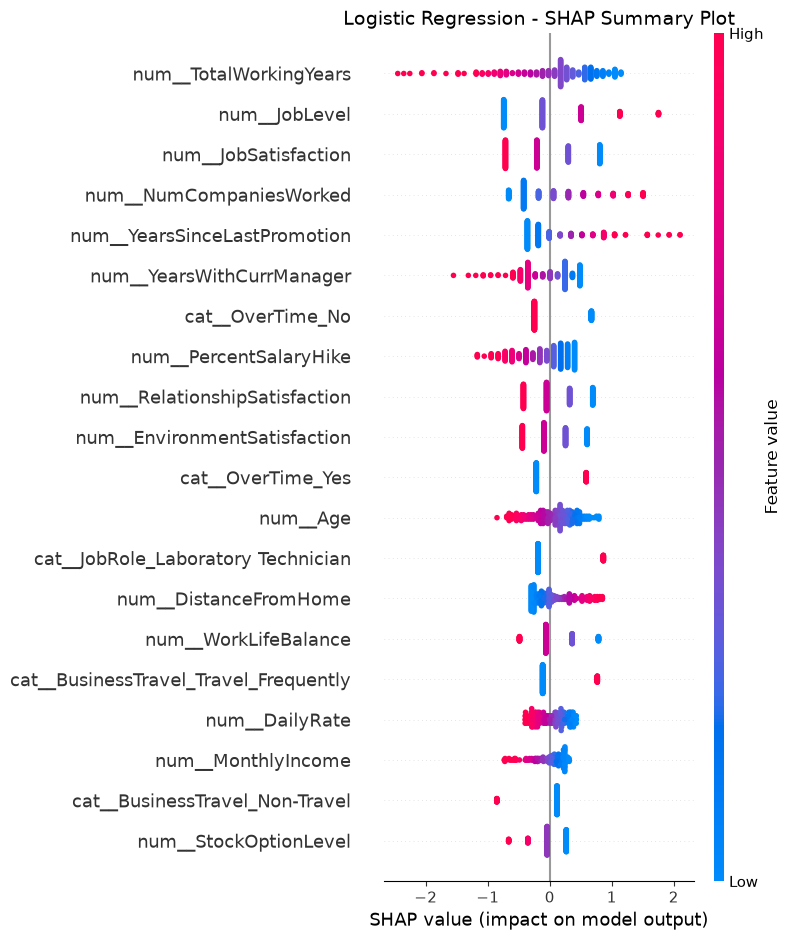

In [24]:
plt.figure(figsize=(12, 9))

shap.summary_plot(
    lr_shap_positive,
    X_validation_processed,
    feature_names=feature_names,
    max_display=20,
    show=False
)

plt.title(
    "Logistic Regression - SHAP Summary Plot",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "19_lr_shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

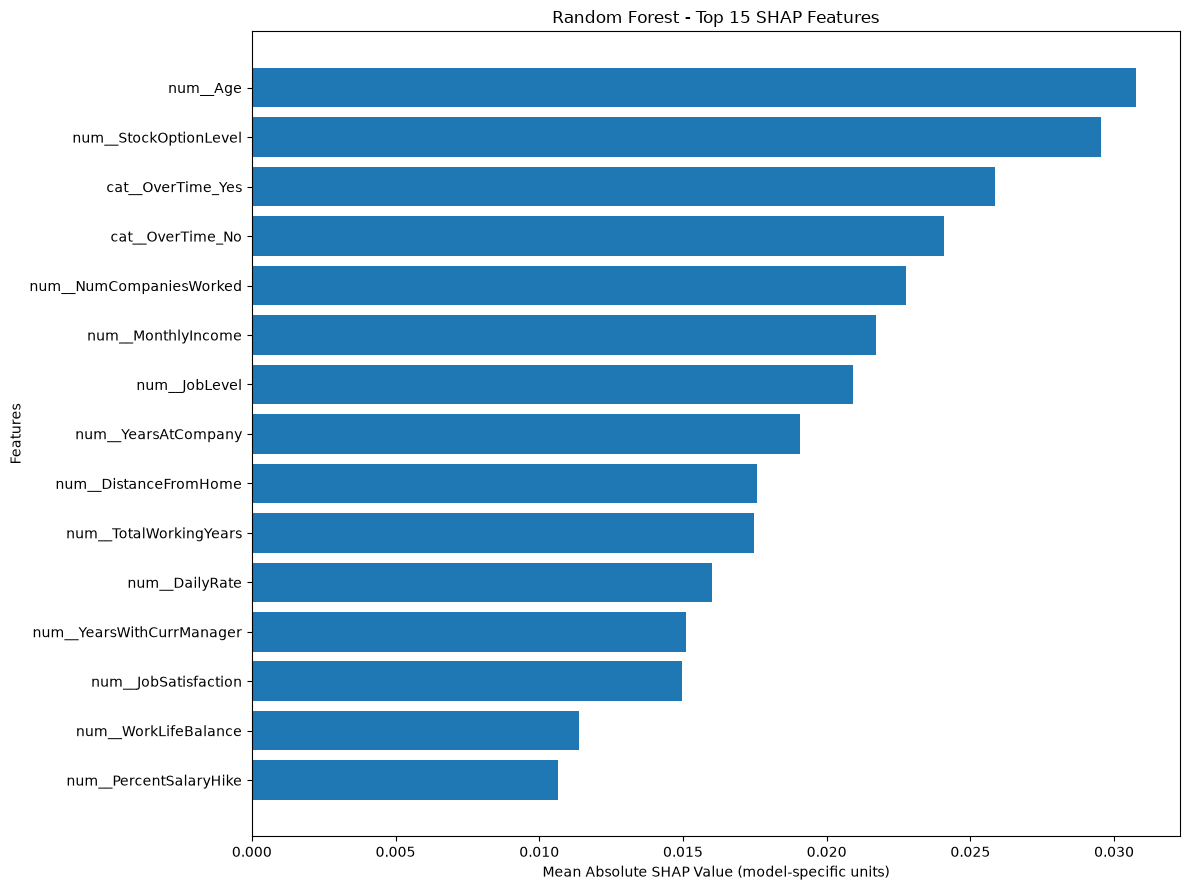

In [25]:
comparison_top = shap_comparison.head(15).copy()

comparison_top = comparison_top.sort_values(
    "Mean_Absolute_SHAP_RandomForest",
    ascending=True
)

plt.figure(figsize=(12, 9))

plt.barh(
    comparison_top["Feature"],
    comparison_top["Mean_Absolute_SHAP_RandomForest"],
    label="Random Forest"
)

plt.xlabel("Mean Absolute SHAP Value (model-specific units)")
plt.ylabel("Features")

plt.title(
    "Random Forest - Top 15 SHAP Features"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "20_rf_top_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [2]:

# STEP 1: Reload saved model and preprocessing artifacts

import joblib
import json
import numpy as np
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path(r"C:\Projects\AI_HR_Prediction")
MODEL_DIR = PROJECT_ROOT / "models"
DATA_DIR = PROJECT_ROOT / "data" / "raw"

# Load model configuration
with open(MODEL_DIR / "attrition_model_config.json", "r") as file:
    model_config = json.load(file)

# Load trained Random Forest model
rf_model = joblib.load(
    MODEL_DIR / model_config["primary_model"]["file"]
)

# Load preprocessing pipeline
preprocessor = joblib.load(
    MODEL_DIR / model_config["preprocessor"]
)

# Load original dataset
df = pd.read_csv(
    DATA_DIR / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
)

# Separate features and target
X = df.drop(
    columns=[
        "Attrition",
        "EmployeeNumber",
        "EmployeeCount",
        "Over18",
        "StandardHours"
    ]
)

y = df["Attrition"].map({"No": 0, "Yes": 1})

print("Random Forest model loaded successfully.")
print("Preprocessor loaded successfully.")
print("Dataset shape:", df.shape)
print("Model features:", rf_model.n_features_in_)


Random Forest model loaded successfully.
Preprocessor loaded successfully.
Dataset shape: (1470, 35)
Model features: 51


In [3]:

from sklearn.model_selection import train_test_split

# Original 80:20 stratified split
X_development, X_final_test, y_development, y_final_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Further split development data into training and validation
X_fit, X_validation, y_fit, y_validation = train_test_split(
    X_development,
    y_development,
    test_size=0.20,
    random_state=42,
    stratify=y_development
)

# Transform validation data using the saved preprocessor
X_validation_processed = preprocessor.transform(X_validation)

print("Validation data reconstructed.")
print("Validation shape:", X_validation.shape)
print("Processed shape:", X_validation_processed.shape)
print("Validation target distribution:")
print(y_validation.value_counts().sort_index())


Validation data reconstructed.
Validation shape: (236, 30)
Processed shape: (236, 51)
Validation target distribution:
Attrition
0    198
1     38
Name: count, dtype: int64


In [4]:

# STEP 3: Prepare employee-level prediction results

# Get Random Forest attrition probabilities
rf_probabilities = rf_model.predict_proba(
    X_validation_processed
)[:, 1]

# Apply configured classification threshold
rf_threshold = model_config["primary_model"]["threshold"]

rf_predictions = (
    rf_probabilities >= rf_threshold
).astype(int)

# Create employee-level results
employee_results = pd.DataFrame({
    "Validation_Index": X_validation.index,
    "Actual_Attrition": y_validation.values,
    "Predicted_Attrition": rf_predictions,
    "Attrition_Probability": rf_probabilities
})

# Convert labels into readable format
employee_results["Actual_Attrition"] = (
    employee_results["Actual_Attrition"].map({0: "No", 1: "Yes"})
)

employee_results["Predicted_Attrition"] = (
    employee_results["Predicted_Attrition"].map({0: "No", 1: "Yes"})
)

# Sort by predicted attrition probability
employee_results = employee_results.sort_values(
    by="Attrition_Probability",
    ascending=False
).reset_index(drop=True)

print("EMPLOYEE-LEVEL PREDICTION RESULTS")
print("=" * 65)

print("\nHighest-risk employees:")
display(employee_results.head(10))

print("\nLowest-risk employees:")
display(employee_results.tail(10))

print("\nTotal validation employees:", len(employee_results))


EMPLOYEE-LEVEL PREDICTION RESULTS

Highest-risk employees:


,Validation_Index,Actual_Attrition,Predicted_Attrition,Attrition_Probability
0,463,Yes,Yes,0.917214
1,1153,Yes,Yes,0.916639
2,1436,No,Yes,0.841389
3,177,Yes,Yes,0.837672
4,1365,Yes,Yes,0.828998
5,656,Yes,Yes,0.810902
6,385,Yes,Yes,0.769731
7,149,No,Yes,0.764086
8,585,Yes,Yes,0.749998
9,589,Yes,Yes,0.745163



Lowest-risk employees:


,Validation_Index,Actual_Attrition,Predicted_Attrition,Attrition_Probability
226,197,No,No,0.109599
227,329,No,No,0.105956
228,1208,No,No,0.099153
229,1044,No,No,0.098788
230,992,No,No,0.096869
231,787,No,No,0.094237
232,814,No,No,0.092052
233,304,No,No,0.087070
234,699,No,No,0.084625
235,894,No,No,0.082813



Total validation employees: 236


In [7]:

# STEP 4A: Recreate SHAP background dataset

# Select 100 samples from the training partition
X_background = X_fit.sample(
    n=100,
    random_state=42
)

# Transform using the already-loaded preprocessing pipeline
X_background_processed = preprocessor.transform(
    X_background
)

# Recreate feature names
feature_names = preprocessor.get_feature_names_out()

print("SHAP background dataset recreated successfully.")
print("Background shape:", X_background_processed.shape)
print("Number of feature names:", len(feature_names))
print("Training samples used:", len(X_background))


SHAP background dataset recreated successfully.
Background shape: (100, 51)
Number of feature names: 51
Training samples used: 100


In [8]:

# STEP 4B: Initialize Random Forest SHAP explainer

rf_explainer = shap.TreeExplainer(
    rf_model,
    data=X_background_processed,
    model_output="probability",
    feature_perturbation="interventional"
)

print("Random Forest SHAP explainer initialized successfully.")
print("Base values:", rf_explainer.expected_value)


Random Forest SHAP explainer initialized successfully.
Base values: [0.68920256 0.31079744]


In [9]:

# STEP 4C: Explain Employee 463

employee_index = 463

# Find employee position in validation dataset
employee_position = X_validation.index.get_loc(employee_index)

# Extract employee's processed features
employee_data = X_validation_processed[
    employee_position:employee_position + 1
]

# Calculate SHAP values
employee_shap_values = rf_explainer.shap_values(employee_data)

# Extract positive class contributions (Attrition = Yes)
employee_shap_positive = np.asarray(
    employee_shap_values
)[0, :, 1]

# Get baseline probability
base_value = float(rf_explainer.expected_value[1])

# Get predicted probability
predicted_probability = rf_model.predict_proba(
    employee_data
)[0, 1]

# Extract feature values
employee_feature_values = (
    employee_data.toarray()[0]
    if hasattr(employee_data, "toarray")
    else np.asarray(employee_data)[0]
)

# Create SHAP explanation object
employee_explanation = shap.Explanation(
    values=employee_shap_positive,
    base_values=base_value,
    data=employee_feature_values,
    feature_names=feature_names
)

print("INDIVIDUAL EMPLOYEE SHAP EXPLANATION")
print("=" * 60)

print("Validation Index:", employee_index)
print("Actual Attrition:", y_validation.iloc[employee_position])
print(f"Predicted Probability: {predicted_probability:.4f}")
print(f"SHAP Base Value: {base_value:.4f}")
print("Number of Features:", len(employee_shap_positive))

reconstructed_probability = (
    base_value + employee_shap_positive.sum()
)

print(
    f"SHAP Reconstructed Probability: "
    f"{reconstructed_probability:.4f}"
)

print("\nSHAP explanation object created successfully.")


INDIVIDUAL EMPLOYEE SHAP EXPLANATION
Validation Index: 463
Actual Attrition: 1
Predicted Probability: 0.9172
SHAP Base Value: 0.3108
Number of Features: 51
SHAP Reconstructed Probability: 0.9171

SHAP explanation object created successfully.


In [11]:

# Define and create figures directory

from pathlib import Path

PROJECT_ROOT = Path(r"C:\Projects\AI_HR_Prediction")

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Save the existing SHAP waterfall plot
waterfall_path = (
    FIGURES_DIR / "21_individual_employee_shap_waterfall.png"
)

plt.savefig(
    waterfall_path,
    dpi=300,
    bbox_inches="tight"
)

print("Waterfall plot saved successfully:")
print(waterfall_path)


Waterfall plot saved successfully:
C:\Projects\AI_HR_Prediction\reports\figures\21_individual_employee_shap_waterfall.png


<Figure size 640x480 with 0 Axes>

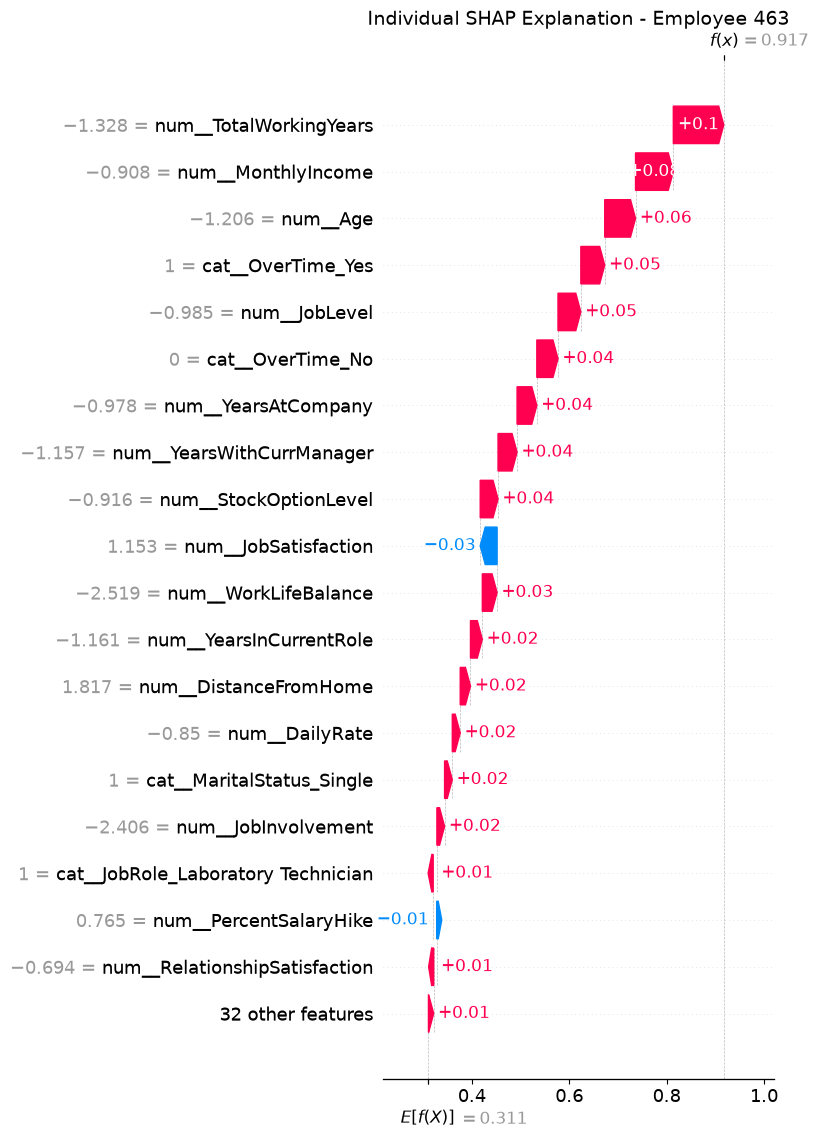

Waterfall plot saved successfully:
C:\Projects\AI_HR_Prediction\reports\figures\21_individual_employee_shap_waterfall.png


In [12]:

# STEP 5: Generate individual employee SHAP waterfall plot

import matplotlib.pyplot as plt
import shap

plt.figure(figsize=(12, 8))

shap.plots.waterfall(
    employee_explanation,
    max_display=20,
    show=False
)

plt.title(
    "Individual SHAP Explanation - Employee 463",
    fontsize=14
)

plt.tight_layout()

# Save the figure
waterfall_path = (
    FIGURES_DIR / "21_individual_employee_shap_waterfall.png"
)

plt.savefig(
    waterfall_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Waterfall plot saved successfully:")
print(waterfall_path)


In [13]:

print("File exists:", waterfall_path.exists())
print("File size:", waterfall_path.stat().st_size, "bytes")


File exists: True
File size: 398883 bytes


INDIVIDUAL EMPLOYEE EXPLANATION
Employee Index: 463
Actual Attrition: 1
Predicted Attrition: Yes
Attrition Probability: 91.72%

Top 10 contributing features:


,Feature,SHAP_Value,Direction,Absolute_SHAP
0,num__TotalWorkingYears,0.103553,Increases attrition risk,0.103553
1,num__MonthlyIncome,0.077571,Increases attrition risk,0.077571
2,num__Age,0.063289,Increases attrition risk,0.063289
3,cat__OverTime_Yes,0.049038,Increases attrition risk,0.049038
4,num__JobLevel,0.046882,Increases attrition risk,0.046882
5,cat__OverTime_No,0.043485,Increases attrition risk,0.043485
6,num__YearsAtCompany,0.040563,Increases attrition risk,0.040563
7,num__YearsWithCurrManager,0.039081,Increases attrition risk,0.039081
8,num__StockOptionLevel,0.036589,Increases attrition risk,0.036589
9,num__JobSatisfaction,-0.034636,Decreases attrition risk,0.034636


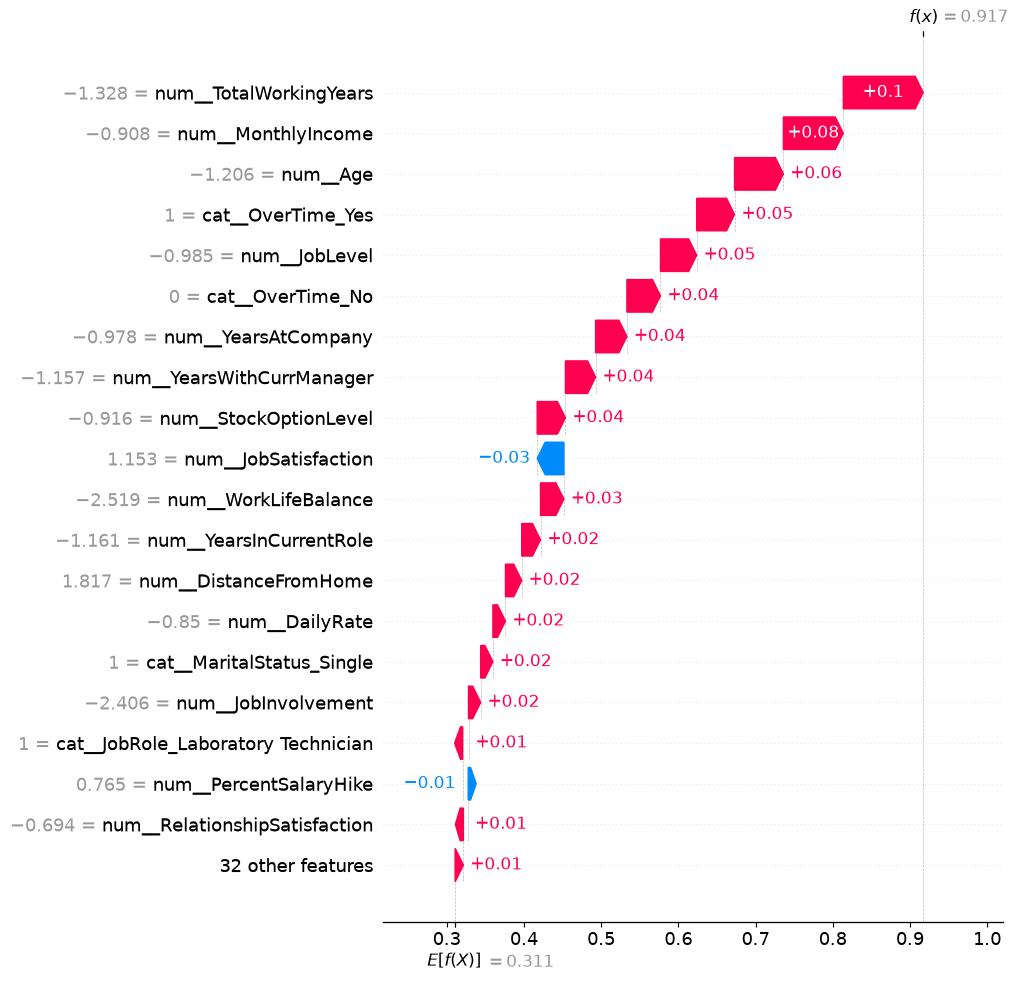

In [14]:

# STEP 6: Reusable Individual Employee SHAP Explanation

def explain_employee(employee_index):

    # Validate employee index
    if employee_index not in X_validation.index:
        raise ValueError(
            f"Employee index {employee_index} not found in validation data."
        )

    # Locate employee
    position = X_validation.index.get_loc(employee_index)

    employee_data = X_validation_processed[position:position + 1]

    # Calculate probability
    probability = rf_model.predict_proba(employee_data)[0, 1]

    # Predict attrition
    prediction = int(
        probability >= model_config["primary_model"]["threshold"]
    )

    # Calculate SHAP values
    shap_values = rf_explainer.shap_values(employee_data)

    positive_shap = np.asarray(shap_values)[0, :, 1]

    # Original feature values after preprocessing
    feature_values = (
        employee_data.toarray()[0]
        if hasattr(employee_data, "toarray")
        else np.asarray(employee_data)[0]
    )

    # Create SHAP explanation
    explanation = shap.Explanation(
        values=positive_shap,
        base_values=float(rf_explainer.expected_value[1]),
        data=feature_values,
        feature_names=feature_names
    )

    # Create feature contribution table
    contribution_table = pd.DataFrame({
        "Feature": feature_names,
        "SHAP_Value": positive_shap,
        "Direction": np.where(
            positive_shap > 0,
            "Increases attrition risk",
            "Decreases attrition risk"
        )
    })

    contribution_table["Absolute_SHAP"] = (
        contribution_table["SHAP_Value"].abs()
    )

    contribution_table = contribution_table.sort_values(
        "Absolute_SHAP",
        ascending=False
    ).reset_index(drop=True)

    print("=" * 65)
    print("INDIVIDUAL EMPLOYEE EXPLANATION")
    print("=" * 65)

    print("Employee Index:", employee_index)
    print("Actual Attrition:", y_validation.iloc[position])
    print("Predicted Attrition:", "Yes" if prediction else "No")
    print(f"Attrition Probability: {probability:.2%}")

    print("\nTop 10 contributing features:")
    display(contribution_table.head(10))

    # Generate waterfall plot
    shap.plots.waterfall(
        explanation,
        max_display=20
    )

    return explanation, contribution_table


# Test the function using Employee 463
employee_463_explanation, employee_463_contributions = (
    explain_employee(463)
)
